# Réseaux récurrents, hybride SARIMA + LSTM et comparaison finale

Ce notebook couvre les sections **4.1** (LSTM et GRU), **4.2** (hybride SARIMA + LSTM) et **6** (comparaison de tous les modèles du groupe, tests de Diebold–Mariano et conclusion).

**Protocole commun au groupe.** Apprentissage jusqu'au 11 juin 2025 (3 450 jours), validation interne du 12 juin au 6 août 2025 (56 jours), test externe du 7 août 2025 au 31 août 2026 (390 jours). Les prévisions sont faites par **blocs de 7 jours** : les valeurs observées d'un bloc ne servent qu'à partir du bloc suivant, et les paramètres des réseaux et du SARIMA restent fixes pendant tout le test. Exception dans la comparaison importée : Prophet est réajusté à chaque origine, uniquement avec les observations alors disponibles. Tous les choix (entrées, nombre d'époques) sont faits sur la validation ; le test sert uniquement à mesurer la précision.

**Entrées.** Les 28 dernières valeurs et le calendrier (jour de la semaine, jour férié), connu à l'avance. Aucune donnée météo ni aucune valeur future n'est utilisée, comme pour les autres modèles du groupe.

| Partie | Contenu |
|---|---|
| Outils communs | réseau, prévision par blocs, entraînement, métriques |
| 4.1 | LSTM et GRU : choix des entrées, validation, test |
| 4.2 | Hybride SARIMA + LSTM : le LSTM prévoit l'erreur du SARIMA |
| 6 | Comparaison des 10 modèles (MSE, RMSE, MAE, MAPE) |
| 6 | Tests de Diebold–Mariano |
| 6 | Prévisions du 1er au 7 septembre 2026, conclusion et limites |

Prérequis : PyTorch, statsmodels et scipy dans l'environnement du notebook (`%pip install torch` au besoin). Dépendances : `pip install -r requirements-lstm-gru.txt`. Depuis la racine : `.venv/Scripts/python.exe scripts/executer_lstm_gru.py` (Windows). Le script enregistre les sorties, figures, tableaux et la conclusion. Le temps de calcul dépend du CPU ; les 5 graines sont toutes exécutées.

In [1]:
import json
import hashlib
import platform
from importlib.metadata import version
import warnings
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.colors import BoundaryNorm, ListedColormap
from scipy import stats
from statsmodels.tsa.statespace.sarimax import SARIMAX
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

ROOT = Path('.') if Path('data/daily.csv').exists() else Path('..')
EXPORTS = ROOT / 'exports' / 'lstm_gru'
FIGURES = ROOT / 'figures' / 'lstm_gru'
EXPORTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
(ROOT / 'forecasts').mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)

WINDOW = 28            # jours d'historique donnés au réseau
BLOCK = 7              # longueur des blocs de prévision, comme pour les autres modèles
HIDDEN = 32            # taille de l'état caché
BATCH = 64
LEARNING_RATE = 1e-3
MAX_EPOCHS = 40
PATIENCE = 7           # arrêt après 7 époques sans amélioration en validation
SEEDS = (42, 43, 44, 45, 46)  # chaque modèle = moyenne de 5 réseaux initialisés différemment

print(f'PyTorch {torch.__version__} — calcul sur CPU pour la reproductibilité')

PyTorch 2.12.0+cpu — calcul sur CPU pour la reproductibilité


In [2]:
# Une couleur fixe par modèle, réutilisée dans toutes les figures.
COLORS = {
    'Observé': '#0b0b0b',
    'SARIMA': '#2a78d6',
    'SARIMA + LSTM': '#eb6834',
    'GRU': '#1baf7a',
    'LSTM': '#eda100',
    'AR-GARCH(1,2)-t': '#e87ba4',
    'VAR(3)': '#008300',
    'VECM(12, r=1)': '#4a3aa7',
    'Prophet': '#e34948',
    'Naïf saisonnier': '#898781',
    'Persistance': '#c3c2b7',
}
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'font.size': 10, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c3c2b7', 'axes.labelcolor': '#52514e', 'axes.titlecolor': '#0b0b0b',
    'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e1e0d9', 'grid.linewidth': 0.6,
    'legend.frameon': False, 'lines.linewidth': 1.5,
})


def save(fig, name):
    fig.savefig(FIGURES / name)
    plt.show()
    plt.close(fig)

## Données et calendrier

Le calendrier est codé par deux variables circulaires pour le jour de la semaine (sinus et cosinus, pour que dimanche soit proche de lundi) et l'indicatrice de jour férié de Fayfa. Il est prolongé jusqu'au 7 septembre 2026 pour la prévision finale.

In [3]:
data = pd.read_csv(ROOT / 'data' / 'daily.csv', parse_dates=['date']).set_index('date').asfreq('D')
consumption = data['conso_gwh'].astype(float)
assert consumption.index.is_unique and consumption.index.is_monotonic_increasing
assert len(consumption) == 3896 and consumption.notna().all() and (consumption > 0).all()
y = consumption.to_numpy()

# Aucun jour férié français ne tombe entre le 1er et le 7 septembre.
calendar_index = pd.date_range(consumption.index[0], '2026-09-07', freq='D')
weekday = calendar_index.dayofweek.to_numpy()
calendar = pd.DataFrame({
    'jour_sin': np.sin(2 * np.pi * weekday / 7),
    'jour_cos': np.cos(2 * np.pi * weekday / 7),
    'ferie': data['ferie'].reindex(calendar_index, fill_value=0).astype(float),
}, index=calendar_index)

N_TRAIN = consumption.index.get_loc(pd.Timestamp('2025-06-11')) + 1
N_DEV = consumption.index.get_loc(pd.Timestamp('2025-08-06')) + 1
N_OBS = len(consumption)
assert (N_TRAIN, N_DEV - N_TRAIN, N_OBS - N_DEV) == (3450, 56, 390)
valid_dates = consumption.index[N_TRAIN:N_DEV]
test_dates = consumption.index[N_DEV:]
final_dates = calendar_index[N_OBS:]

pd.DataFrame({
    'segment': ['Apprentissage', 'Validation interne', 'Test externe', 'Prévision finale'],
    'début': [consumption.index[0], valid_dates[0], test_dates[0], final_dates[0]],
    'fin': [consumption.index[N_TRAIN - 1], valid_dates[-1], test_dates[-1], final_dates[-1]],
    'jours': [N_TRAIN, len(valid_dates), len(test_dates), len(final_dates)],
})

,segment,début,fin,jours
0,Apprentissage,2016-01-01,2025-06-11,3450
1,Validation interne,2025-06-12,2025-08-06,56
2,Test externe,2025-08-07,2026-08-31,390
3,Prévision finale,2026-09-01,2026-09-07,7


## Outils communs

Les mêmes fonctions servent aux réseaux directs (4.1) et au LSTM des erreurs (4.2) :

- `RecurrentForecaster` : une couche LSTM ou GRU lit les 28 derniers jours (valeur et calendrier). Une couche linéaire combine son dernier état avec le calendrier du jour à prévoir.
- `forecast_blocks` : prévision récursive par blocs de 7 jours. Dans un bloc, chaque prévision sert d'entrée pour le jour suivant ; les vraies valeurs ne sont ajoutées qu'au bloc suivant.
- `train_network` : perte quadratique, optimiseur Adam. En validation, on garde la meilleure époque (arrêt anticipé) ; au réajustement, on entraîne le nombre d'époques retenu.
- `scores` : MSE, RMSE, MAE, MAPE et biais (prévision − observation).

Les séries sont centrées-réduites avec la moyenne et l'écart-type de la seule période d'apprentissage de chaque ajustement.

In [4]:
class RecurrentForecaster(nn.Module):
    """Couche LSTM ou GRU suivie d'une couche linéaire."""

    def __init__(self, kind, n_calendar):
        super().__init__()
        layer = {'LSTM': nn.LSTM, 'GRU': nn.GRU}[kind]
        self.recurrent = layer(input_size=1 + n_calendar, hidden_size=HIDDEN, batch_first=True)
        self.output = nn.Linear(HIDDEN + n_calendar, 1)

    def forward(self, window, target_calendar):
        states, _ = self.recurrent(window)
        return self.output(torch.cat([states[:, -1], target_calendar], dim=1)).squeeze(1)


class Standardizer:
    """Centre et réduit avec la moyenne et l'écart-type de la période d'apprentissage."""

    def __init__(self, values):
        values = np.asarray(values, dtype=float)
        if values.ndim != 1 or not len(values) or not np.isfinite(values).all():
            raise ValueError('La série à normaliser doit être un vecteur fini non vide.')
        self.mean, self.std = float(np.mean(values)), float(np.std(values))
        if self.std <= 0:
            raise ValueError('Impossible de normaliser une série constante.')

    def transform(self, values):
        return (np.asarray(values) - self.mean) / self.std

    def inverse(self, values):
        return np.asarray(values) * self.std + self.mean


def network_inputs(history, calendar_values, t):
    """Entrées pour prévoir le jour t : les WINDOW dernières valeurs de `history`
    (qui s'arrête à t - 1) avec leur calendrier, puis le calendrier du jour t."""
    window = np.column_stack([history[-WINDOW:], calendar_values[t - WINDOW:t]])
    return (torch.tensor(window[None], dtype=torch.float32),
            torch.tensor(calendar_values[t][None], dtype=torch.float32))


def training_set(values, calendar_values, end):
    """Toutes les fenêtres dont la cible est antérieure à la position `end`."""
    windows, calendars = zip(*(network_inputs(values[:t], calendar_values, t) for t in range(WINDOW, end)))
    targets = torch.tensor(values[WINDOW:end], dtype=torch.float32)
    return TensorDataset(torch.cat(windows), torch.cat(calendars), targets)


def forecast_blocks(model, values, calendar_values, start, stop):
    """Prévisions récursives par blocs de BLOCK jours, de la position `start` à `stop` (exclue)."""
    if not WINDOW <= start <= len(values) or not start <= stop <= len(calendar_values):
        raise ValueError('Historique ou calendrier insuffisant pour les dates demandées.')
    if stop > len(values) + BLOCK:
        raise ValueError('Les observations doivent être disponibles avant chaque nouveau bloc.')
    model.eval()
    predictions = []
    with torch.no_grad():
        for block_start in range(start, stop, BLOCK):
            history = list(values[block_start - WINDOW:block_start])
            for t in range(block_start, min(block_start + BLOCK, stop)):
                history.append(model(*network_inputs(history, calendar_values, t)).item())
            predictions.extend(history[WINDOW:])
    return np.asarray(predictions)


def train_network(kind, values, calendar_values, end, seed, epochs=MAX_EPOCHS, validation_rmse=None):
    """Entraîne un réseau sur les cibles antérieures à `end`.

    Avec `validation_rmse` (fonction modèle -> RMSE de validation), on garde la meilleure
    époque et on s'arrête après PATIENCE époques sans progrès. Sans elle, on entraîne
    exactement `epochs` époques.
    """
    print(f'{kind}, graine {seed}, apprentissage {end} jours, maximum {epochs} époques', flush=True)
    torch.manual_seed(seed)
    model = RecurrentForecaster(kind, calendar_values.shape[1])
    loader = DataLoader(training_set(values, calendar_values, end), batch_size=BATCH,
                        shuffle=True, generator=torch.Generator().manual_seed(seed))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    curve, best_rmse, best_epoch, best_state = [], np.inf, epochs, None
    for epoch in range(1, epochs + 1):
        model.train()
        for windows, calendars, targets in loader:
            optimizer.zero_grad()
            loss = nn.functional.mse_loss(model(windows, calendars), targets)
            if not torch.isfinite(loss):
                raise FloatingPointError('Perte non finie pendant l’entraînement.')
            loss.backward()
            optimizer.step()
        if validation_rmse is None:
            continue
        curve.append(validation_rmse(model))
        if curve[-1] < best_rmse:
            best_rmse, best_epoch, best_state = curve[-1], epoch, deepcopy(model.state_dict())
        elif epoch - best_epoch >= PATIENCE:
            break
    if best_state is not None:
        model.load_state_dict(best_state)
    print(f'  terminé : {epoch} époques exécutées, {best_epoch} retenues', flush=True)
    return model, best_epoch, curve


def rmse(observed, predicted):
    return float(np.sqrt(np.mean((np.asarray(predicted) - np.asarray(observed)) ** 2)))


def scores(observed, predicted):
    observed, predicted = np.asarray(observed, dtype=float), np.asarray(predicted, dtype=float)
    if observed.ndim != 1 or observed.shape != predicted.shape or not len(observed):
        raise ValueError('Observations et prévisions doivent être deux vecteurs de même longueur.')
    if not np.isfinite(observed).all() or not np.isfinite(predicted).all() or (observed == 0).any():
        raise ValueError('Valeurs non finies ou observations nulles (MAPE indéfinie).')
    errors = predicted - observed
    return {'MSE': np.mean(errors ** 2), 'RMSE': np.sqrt(np.mean(errors ** 2)),
            'MAE': np.mean(np.abs(errors)), 'MAPE (%)': 100 * np.mean(np.abs(errors / observed)),
            'biais': np.mean(errors)}


def validation_table(runs, label):
    """RMSE de validation de la moyenne des 5 réseaux, pour chaque configuration."""
    rows = []
    for inputs, seed_runs in runs.items():
        ensemble = np.mean([run['valid'] for run in seed_runs], axis=0)
        rows.append({'modèle': label, 'entrées': inputs,
                     'RMSE validation': rmse(y[N_TRAIN:N_DEV], ensemble),
                     'RMSE moyenne d’un réseau seul': np.mean([rmse(y[N_TRAIN:N_DEV], run['valid']) for run in seed_runs]),
                     'époques retenues': ', '.join(str(run['epoch']) for run in seed_runs)})
    return pd.DataFrame(rows)


def plot_validation_curves(axis, seed_runs, label):
    for run in seed_runs:
        epochs = np.arange(1, len(run['curve']) + 1)
        axis.plot(epochs, run['curve'], color=COLORS[label], linewidth=1, alpha=0.8)
        axis.plot(run['epoch'], run['curve'][run['epoch'] - 1], 'o', color=COLORS[label], markersize=6)
    axis.set(title=label, xlabel='Époque', ylabel='RMSE de validation (GWh/jour)')

## 4.1 LSTM et GRU

Un **LSTM** (*Long Short-Term Memory*) garde une mémoire interne contrôlée par trois portes : la porte d'oubli efface, la porte d'entrée écrit et la porte de sortie lit. Un **GRU** (*Gated Recurrent Unit*) simplifie ce mécanisme avec deux portes (mise à jour et réinitialisation) et a donc moins de paramètres. Les deux réseaux ont ici la même taille (32 unités), la même fenêtre de 28 jours et le même protocole : seule la cellule récurrente diffère.

**Choix des entrées sur la validation.** Deux versions sont comparées : la consommation seule, et la consommation avec le calendrier. Chaque version est entraînée avec 5 graines aléatoires. La prévision retenue est la moyenne des 5 réseaux, ce qui réduit la dépendance à l'initialisation. Le nombre d'époques de chaque réseau est choisi par arrêt anticipé sur les 56 jours de validation.

In [5]:
INPUT_SETS = {
    'consommation seule': calendar.iloc[:, :0].to_numpy(),
    'consommation + calendrier': calendar.to_numpy(),
}
train_scaler = Standardizer(y[:N_TRAIN])
y_train_scaled = train_scaler.transform(y)


def validate_direct(kind, calendar_values, seed):
    """Apprentissage jusqu'au 11 juin 2025, arrêt anticipé sur la validation."""
    def predict(model):
        return train_scaler.inverse(forecast_blocks(model, y_train_scaled, calendar_values, N_TRAIN, N_DEV))

    model, epoch, curve = train_network(kind, y_train_scaled, calendar_values, N_TRAIN, seed,
                                        validation_rmse=lambda model: rmse(y[N_TRAIN:N_DEV], predict(model)))
    return {'epoch': epoch, 'curve': curve, 'valid': predict(model)}


direct_validation = {
    kind: {inputs: [validate_direct(kind, calendar_values, seed) for seed in SEEDS]
           for inputs, calendar_values in INPUT_SETS.items()}
    for kind in ('LSTM', 'GRU')
}
direct_summary = pd.concat([validation_table(runs, kind) for kind, runs in direct_validation.items()], ignore_index=True)
selected_inputs = (direct_summary.loc[direct_summary.groupby('modèle')['RMSE validation'].idxmin()]
                   .set_index('modèle')['entrées'].to_dict())
direct_summary.to_csv(EXPORTS / 'validation_lstm_gru.csv', index=False)
print('Entrées retenues :', selected_inputs)
direct_summary.round(2)

LSTM, graine 42, apprentissage 3450 jours, maximum 40 époques


  terminé : 40 époques exécutées, 34 retenues


LSTM, graine 43, apprentissage 3450 jours, maximum 40 époques


  terminé : 23 époques exécutées, 16 retenues


LSTM, graine 44, apprentissage 3450 jours, maximum 40 époques


...

  terminé : 34 époques exécutées, 27 retenues


GRU, graine 46, apprentissage 3450 jours, maximum 40 époques


  terminé : 40 époques exécutées, 36 retenues


Entrées retenues : {'GRU': 'consommation + calendrier', 'LSTM': 'consommation + calendrier'}


,modèle,entrées,RMSE validation,RMSE moyenne d’un réseau seul,époques retenues
0,LSTM,consommation seule,46.55,51.77,"34, 16, 28, 28, 25"
1,LSTM,consommation + calendrier,39.37,40.08,"33, 36, 26, 33, 14"
2,GRU,consommation seule,50.06,56.41,"35, 23, 38, 7, 5"
3,GRU,consommation + calendrier,38.87,39.27,"35, 36, 34, 27, 36"


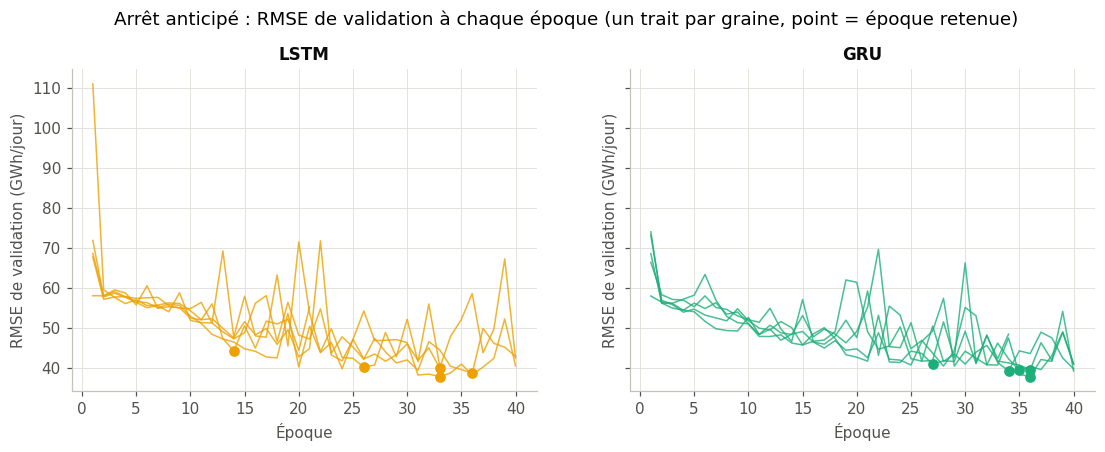

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for axis, kind in zip(axes, ('LSTM', 'GRU')):
    plot_validation_curves(axis, direct_validation[kind][selected_inputs[kind]], kind)
fig.suptitle('Arrêt anticipé : RMSE de validation à chaque époque (un trait par graine, point = époque retenue)', y=1.02)
save(fig, '41_courbes_validation.png')

### Réajustement et test externe

Chaque réseau est réentraîné jusqu'au 6 août 2025 avec le nombre d'époques choisi en validation, puis prévoit les 390 jours de test par blocs de 7 jours. Il est ensuite réentraîné de la même façon sur toutes les données pour la prévision du 1er au 7 septembre 2026. Le test n'intervient dans aucun choix.

In [7]:
dev_scaler, all_scaler = Standardizer(y[:N_DEV]), Standardizer(y)
y_dev_scaled, y_all_scaled = dev_scaler.transform(y), all_scaler.transform(y)


def refit_direct(kind, calendar_values, seed, epochs):
    """Réajustement à nombre d'époques fixé : test externe, puis prévision finale."""
    model, _, _ = train_network(kind, y_dev_scaled, calendar_values, N_DEV, seed, epochs=epochs)
    test = dev_scaler.inverse(forecast_blocks(model, y_dev_scaled, calendar_values, N_DEV, N_OBS))
    model, _, _ = train_network(kind, y_all_scaled, calendar_values, N_OBS, seed, epochs=epochs)
    final = all_scaler.inverse(forecast_blocks(model, y_all_scaled, calendar_values, N_OBS, N_OBS + BLOCK))
    return test, final


test_predictions, final_forecasts = {}, {}
for kind, inputs in selected_inputs.items():
    refits = [refit_direct(kind, INPUT_SETS[inputs], seed, run['epoch'])
              for seed, run in zip(SEEDS, direct_validation[kind][inputs])]
    test_predictions[kind] = np.mean([test for test, _ in refits], axis=0)
    final_forecasts[kind] = np.mean([final for _, final in refits], axis=0)

pd.DataFrame({kind: scores(y[N_DEV:], predicted) for kind, predicted in test_predictions.items()}).T.round(2)

GRU, graine 42, apprentissage 3506 jours, maximum 35 époques


  terminé : 35 époques exécutées, 35 retenues


GRU, graine 42, apprentissage 3896 jours, maximum 35 époques


  terminé : 35 époques exécutées, 35 retenues


GRU, graine 43, apprentissage 3506 jours, maximum 36 époques


...

LSTM, graine 46, apprentissage 3506 jours, maximum 14 époques


  terminé : 14 époques exécutées, 14 retenues


LSTM, graine 46, apprentissage 3896 jours, maximum 14 époques


  terminé : 14 époques exécutées, 14 retenues


,MSE,RMSE,MAE,MAPE (%),biais
GRU,5836.62,76.40,52.40,4.16,-13.89
LSTM,5634.84,75.07,50.26,3.96,-8.23


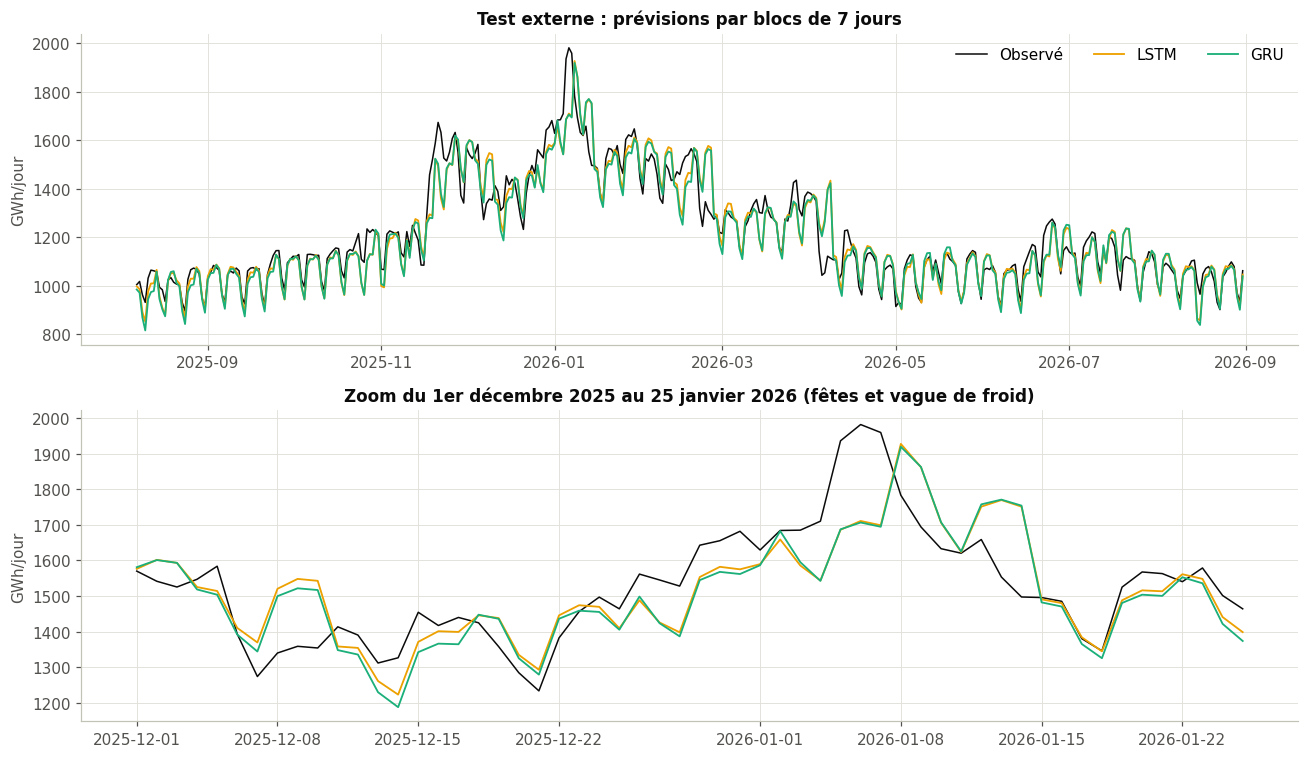

In [8]:
zoom = slice('2025-12-01', '2026-01-25')
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for axis, period in zip(axes, (slice(None), zoom)):
    observed = consumption.iloc[N_DEV:].loc[period]
    axis.plot(observed.index, observed, color=COLORS['Observé'], linewidth=1, label='Observé')
    for kind in ('LSTM', 'GRU'):
        predicted = pd.Series(test_predictions[kind], index=test_dates).loc[period]
        axis.plot(predicted.index, predicted, color=COLORS[kind], linewidth=1.2, label=kind)
    axis.set_ylabel('GWh/jour')
axes[0].set_title('Test externe : prévisions par blocs de 7 jours')
axes[1].set_title('Zoom du 1er décembre 2025 au 25 janvier 2026 (fêtes et vague de froid)')
axes[0].legend(ncol=3, loc='upper right')
fig.tight_layout()
save(fig, '41_test_lstm_gru.png')

## 4.2 Hybride SARIMA + LSTM

Le SARIMA(2,1,1)(0,1,1)[7] retenu en section 3.1 fournit une première prévision $\hat y^{\text{SARIMA}}_t$. Un LSTM apprend ensuite à prévoir son erreur $e_t = y_t - \hat y^{\text{SARIMA}}_t$, et la prévision hybride vaut $\hat y_t = \hat y^{\text{SARIMA}}_t + \hat e_t$.

**Erreurs d'apprentissage.** Le LSTM doit apprendre sur des erreurs semblables à celles du test : des erreurs de prévision par blocs de 7 jours, à paramètres fixes. On les génère du 5 janvier 2017 (après un an de démarrage du filtre) jusqu'à la fin de chaque période d'ajustement, soit environ 3 000 erreurs. Les paramètres du SARIMA sont estimés sur cette même période : ces erreurs sont donc *pseudo* hors échantillon (les paramètres ont vu les données, les états non).

Trois étapes, comme pour les réseaux directs :

| Étape | SARIMA estimé jusqu'au | LSTM des erreurs |
|---|---|---|
| Validation | 11 juin 2025 | choix des entrées et des époques sur les 56 jours de validation |
| Test | 6 août 2025 (modèle de la section 3.1) | réentraîné, puis corrige les 390 jours de test |
| Prévision finale | 31 août 2026 | réentraîné, puis corrige le 1er–7 septembre 2026 |

On vérifie d'abord que les prévisions SARIMA recalculées ici coïncident avec celles exportées en section 3.1.

In [9]:
selection = json.loads((ROOT / 'exports' / 'selection_avant_test.json').read_text(encoding='utf-8'))
SARIMA_SPEC = dict(order=tuple(selection['order']), seasonal_order=tuple(selection['seasonal_order']),
                   trend=selection['trend'], enforce_stationarity=True, enforce_invertibility=True)
ERRORS_START = consumption.index.get_loc(pd.Timestamp('2017-01-05'))  # un jeudi, comme le début du test
assert (N_TRAIN - ERRORS_START) % BLOCK == 0 and (N_DEV - ERRORS_START) % BLOCK == 0


def sarima_blocked_forecasts(fit_end):
    """Estime le SARIMA sur les fit_end premiers jours, puis prévoit par blocs de 7 jours
    à paramètres fixes, du 5 janvier 2017 jusqu'au 7 septembre 2026."""
    with warnings.catch_warnings():
        fitted = SARIMAX(consumption.iloc[:fit_end], **SARIMA_SPEC).fit(disp=False, maxiter=500)
        if not fitted.mle_retvals.get('converged', False):
            raise RuntimeError(f'SARIMA non convergé pour fit_end={fit_end}')
        params = fitted.params
        state = SARIMAX(consumption.iloc[:ERRORS_START], **SARIMA_SPEC).filter(params)
        starts = list(range(ERRORS_START, N_OBS, BLOCK)) + [N_OBS]
        forecasts = []
        for block_start, block_stop in zip(starts, starts[1:] + [N_OBS + BLOCK]):
            forecasts.extend(np.asarray(state.get_forecast(block_stop - block_start).predicted_mean))
            if block_stop <= N_OBS:
                state = state.extend(y[block_start:block_stop])
    return np.asarray(forecasts)


sarima_runs = {stage: sarima_blocked_forecasts(fit_end)
               for stage, fit_end in (('validation', N_TRAIN), ('test', N_DEV), ('final', N_OBS))}
E_TRAIN, E_DEV, E_OBS = (n - ERRORS_START for n in (N_TRAIN, N_DEV, N_OBS))


def official_sarima(file_name):
    frame = pd.read_csv(ROOT / 'exports' / file_name, parse_dates=['date'])
    if 'modele' in frame:
        frame = frame[frame['modele'] == selection['modele']]
    return frame.set_index('date')['prevision']


reproduction = pd.DataFrame({
    'étape': ['validation', 'test', 'prévision finale'],
    'fichier de la section 3.1': ['predictions_validation_complement.csv', 'predictions_test.csv', 'previsions_7j.csv'],
    'écart maximal (GWh)': [
        np.abs(sarima_runs['validation'][E_TRAIN:E_DEV] - official_sarima('predictions_validation_complement.csv').loc[valid_dates]).max(),
        np.abs(sarima_runs['test'][E_DEV:E_OBS] - official_sarima('predictions_test.csv').loc[test_dates]).max(),
        np.abs(sarima_runs['final'][E_OBS:] - official_sarima('previsions_7j.csv').loc[final_dates]).max(),
    ],
})
assert (reproduction['écart maximal (GWh)'] < 0.1).all()
reproduction.round(4)

,étape,fichier de la section 3.1,écart maximal (GWh)
0,validation,predictions_validation_complement.csv,0.0094
1,test,predictions_test.csv,0.0192
2,prévision finale,previsions_7j.csv,0.0003


Les écarts sont inférieurs à 0,1 GWh, sur des valeurs autour de 1 000 à 2 000 GWh : le SARIMA recalculé est bien celui de la section 3.1 (les différences viennent des versions de statsmodels). On choisit maintenant les entrées et les époques du LSTM des erreurs sur la validation, avec les mêmes deux options d'entrées que pour les réseaux directs.

In [10]:
validation_errors = y[ERRORS_START:] - sarima_runs['validation'][:E_OBS]
error_train_scaler = Standardizer(validation_errors[:E_TRAIN])
validation_errors_scaled = error_train_scaler.transform(validation_errors)
sarima_valid = sarima_runs['validation'][E_TRAIN:E_DEV]


def residual_inputs(inputs):
    return INPUT_SETS[inputs][ERRORS_START:]


def validate_hybrid(calendar_values, seed):
    """LSTM des erreurs entraîné jusqu'au 11 juin 2025, arrêt anticipé sur la validation."""
    def predict(model):
        correction = forecast_blocks(model, validation_errors_scaled, calendar_values, E_TRAIN, E_DEV)
        return sarima_valid + error_train_scaler.inverse(correction)

    model, epoch, curve = train_network('LSTM', validation_errors_scaled, calendar_values, E_TRAIN, seed,
                                        validation_rmse=lambda model: rmse(y[N_TRAIN:N_DEV], predict(model)))
    return {'epoch': epoch, 'curve': curve, 'valid': predict(model)}


hybrid_validation = {inputs: [validate_hybrid(residual_inputs(inputs), seed) for seed in SEEDS]
                     for inputs in INPUT_SETS}
hybrid_summary = validation_table(hybrid_validation, 'SARIMA + LSTM')
hybrid_inputs = hybrid_summary.loc[hybrid_summary['RMSE validation'].idxmin(), 'entrées']
hybrid_summary.to_csv(EXPORTS / 'validation_hybride.csv', index=False)
print(f'SARIMA seul sur la même validation : RMSE {rmse(y[N_TRAIN:N_DEV], sarima_valid):.2f} GWh/jour')
print(f'Entrées retenues pour le LSTM des erreurs : {hybrid_inputs}')
hybrid_summary.round(2)

LSTM, graine 42, apprentissage 3080 jours, maximum 40 époques


  terminé : 8 époques exécutées, 1 retenues


LSTM, graine 43, apprentissage 3080 jours, maximum 40 époques


  terminé : 8 époques exécutées, 1 retenues


LSTM, graine 44, apprentissage 3080 jours, maximum 40 époques


...

  terminé : 31 époques exécutées, 24 retenues


LSTM, graine 46, apprentissage 3080 jours, maximum 40 époques


  terminé : 35 époques exécutées, 28 retenues


SARIMA seul sur la même validation : RMSE 42.67 GWh/jour
Entrées retenues pour le LSTM des erreurs : consommation + calendrier


,modèle,entrées,RMSE validation,RMSE moyenne d’un réseau seul,époques retenues
0,SARIMA + LSTM,consommation seule,44.81,44.87,"1, 1, 1, 1, 1"
1,SARIMA + LSTM,consommation + calendrier,36.60,37.20,"37, 22, 14, 24, 28"


In [11]:
def hybrid_forecast(stage, fit_end, stop, calendar_values, seed, epochs):
    """Réentraîne le LSTM sur les erreurs antérieures à fit_end, puis corrige le SARIMA jusqu'à stop."""
    errors = y[ERRORS_START:] - sarima_runs[stage][:E_OBS]
    scaler = Standardizer(errors[:fit_end])
    scaled = scaler.transform(errors)
    model, _, _ = train_network('LSTM', scaled, calendar_values, fit_end, seed, epochs=epochs)
    correction = scaler.inverse(forecast_blocks(model, scaled, calendar_values, fit_end, stop))
    return sarima_runs[stage][fit_end:stop] + correction


hybrid_calendar = residual_inputs(hybrid_inputs)
hybrid_epochs = [run['epoch'] for run in hybrid_validation[hybrid_inputs]]
configuration = {
    'window': WINDOW, 'block': BLOCK, 'hidden': HIDDEN, 'batch': BATCH,
    'learning_rate': LEARNING_RATE, 'max_epochs': MAX_EPOCHS, 'patience': PATIENCE, 'seeds': list(SEEDS),
    'direct': {kind: {'inputs': inputs, 'epochs': [run['epoch'] for run in direct_validation[kind][inputs]]}
               for kind, inputs in selected_inputs.items()},
    'hybrid': {'inputs': hybrid_inputs, 'epochs': hybrid_epochs},
    'selection': 'validation interne uniquement ; architecture et graines fixées avant exécution',
}
(EXPORTS / 'configuration.json').write_text(json.dumps(configuration, ensure_ascii=False, indent=2), encoding='utf-8')
test_predictions['SARIMA + LSTM'] = np.mean(
    [hybrid_forecast('test', E_DEV, E_OBS, hybrid_calendar, seed, epochs) for seed, epochs in zip(SEEDS, hybrid_epochs)], axis=0)
final_forecasts['SARIMA + LSTM'] = np.mean(
    [hybrid_forecast('final', E_OBS, E_OBS + BLOCK, hybrid_calendar, seed, epochs) for seed, epochs in zip(SEEDS, hybrid_epochs)], axis=0)
final_forecasts['SARIMA'] = sarima_runs['final'][E_OBS:]

sarima_test = official_sarima('predictions_test.csv').loc[test_dates].to_numpy()
pd.DataFrame({'SARIMA': scores(y[N_DEV:], sarima_test),
              'SARIMA + LSTM': scores(y[N_DEV:], test_predictions['SARIMA + LSTM'])}).T.round(2)

LSTM, graine 42, apprentissage 3136 jours, maximum 37 époques


  terminé : 37 époques exécutées, 37 retenues


LSTM, graine 43, apprentissage 3136 jours, maximum 22 époques


  terminé : 22 époques exécutées, 22 retenues


LSTM, graine 44, apprentissage 3136 jours, maximum 14 époques


...

LSTM, graine 45, apprentissage 3526 jours, maximum 24 époques


  terminé : 24 époques exécutées, 24 retenues


LSTM, graine 46, apprentissage 3526 jours, maximum 28 époques


  terminé : 28 époques exécutées, 28 retenues


,MSE,RMSE,MAE,MAPE (%),biais
SARIMA,6786.82,82.38,53.12,4.13,1.25
SARIMA + LSTM,6387.63,79.92,53.84,4.27,8.51


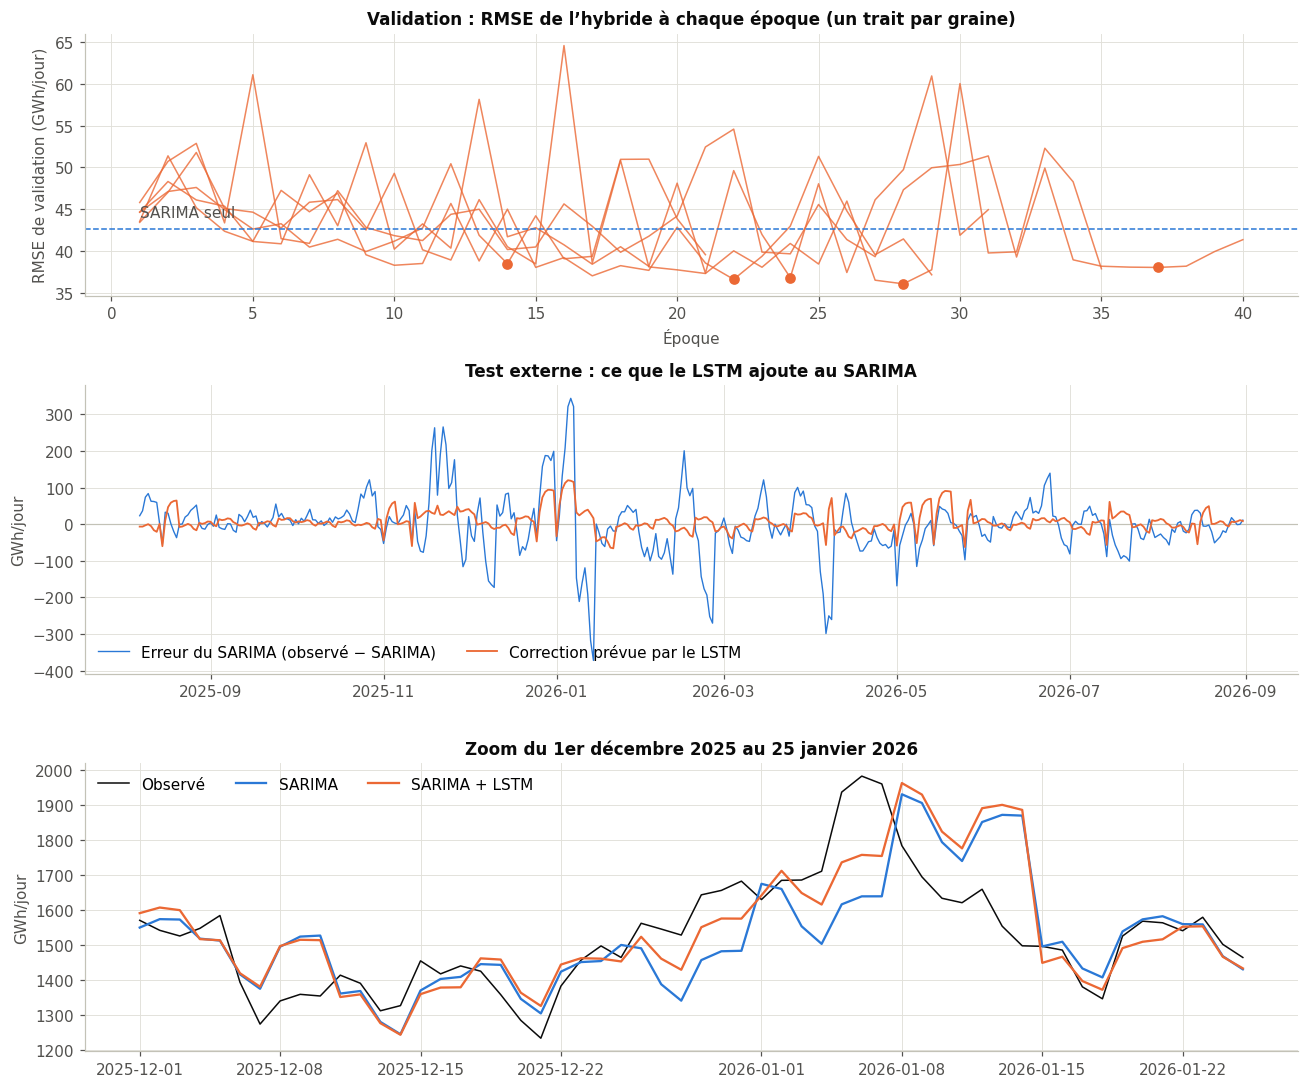

In [12]:
sarima_error = pd.Series(y[N_DEV:] - sarima_test, index=test_dates)
correction = pd.Series(test_predictions['SARIMA + LSTM'] - sarima_test, index=test_dates)

fig, axes = plt.subplots(3, 1, figsize=(12, 10), gridspec_kw={'height_ratios': [1, 1.1, 1.1]})
plot_validation_curves(axes[0], hybrid_validation[hybrid_inputs], 'SARIMA + LSTM')
axes[0].axhline(rmse(y[N_TRAIN:N_DEV], sarima_valid), color=COLORS['SARIMA'], linestyle='--', linewidth=1)
axes[0].text(1, rmse(y[N_TRAIN:N_DEV], sarima_valid) + 1, 'SARIMA seul', color='#52514e', va='bottom')
axes[0].set_title('Validation : RMSE de l’hybride à chaque époque (un trait par graine)')

axes[1].axhline(0, color='#c3c2b7', linewidth=0.8)
axes[1].plot(sarima_error.index, sarima_error, color=COLORS['SARIMA'], linewidth=0.9, label='Erreur du SARIMA (observé − SARIMA)')
axes[1].plot(correction.index, correction, color=COLORS['SARIMA + LSTM'], linewidth=1.2, label='Correction prévue par le LSTM')
axes[1].set(title='Test externe : ce que le LSTM ajoute au SARIMA', ylabel='GWh/jour')
axes[1].legend(ncol=2, loc='lower left')

observed = consumption.loc[zoom]
axes[2].plot(observed.index, observed, color=COLORS['Observé'], linewidth=1, label='Observé')
axes[2].plot(observed.index, pd.Series(sarima_test, index=test_dates).loc[zoom], color=COLORS['SARIMA'], label='SARIMA')
axes[2].plot(observed.index, pd.Series(test_predictions['SARIMA + LSTM'], index=test_dates).loc[zoom],
             color=COLORS['SARIMA + LSTM'], label='SARIMA + LSTM')
axes[2].set(title='Zoom du 1er décembre 2025 au 25 janvier 2026', ylabel='GWh/jour')
axes[2].legend(ncol=3, loc='upper left')
fig.tight_layout()
save(fig, '42_hybride_sarima_lstm.png')

## 6. Comparaison de tous les modèles

Les prévisions des autres membres du groupe sont relues dans leurs exports. Tous les modèles prévoient les **mêmes 390 jours** avec les **mêmes 55 blocs complets de 7 jours et un dernier bloc de 5 jours** ; le code le vérifie (dates, observations et horizons identiques).

| Modèle | Section | Fichier |
|---|---|---|
| SARIMA(2,1,1)(0,1,1)[7] | 3.1 | `exports/predictions_test.csv` |
| VAR(3) avec calendrier | 3.2 | `exports/ghada/predictions_test_detail.csv` |
| VECM(k = 12, r = 1) | 3.3 | idem |
| AR-GARCH(1,2)-t | 4.3 | idem |
| Prophet (réajusté chaque semaine) | 4.3 | idem |
| LSTM, GRU | 4.1 | ce notebook |
| SARIMA + LSTM | 4.2 | ce notebook |
| Naïf saisonnier (semaine précédente), persistance (dernière valeur) | références | `exports/predictions_test.csv` |

Le SARIMA réestimé en R (section 3, Anwar) reproduit celui de Python (RMSE 82,38 contre 82,38) ; il n'est pas compté deux fois.

Métriques, avec $e_t = \hat y_t - y_t$ sur les $n = 390$ jours : $\text{MSE} = \frac1n\sum e_t^2$, $\text{RMSE} = \sqrt{\text{MSE}}$ (en GWh/jour), $\text{MAE} = \frac1n\sum |e_t|$, $\text{MAPE} = \frac{100}{n}\sum |e_t / y_t|$. La RMSE pénalise davantage les grosses erreurs (vagues de froid) ; la MAE et la MAPE mesurent l'erreur typique.

In [13]:
OTHER_MODELS = {
    'SARIMA': ('predictions_test.csv', selection['modele']),
    'VAR(3)': ('ghada/predictions_test_detail.csv', 'var'),
    'VECM(12, r=1)': ('ghada/predictions_test_detail.csv', 'vecm'),
    'AR-GARCH(1,2)-t': ('ghada/predictions_test_detail.csv', 'garch'),
    'Prophet': ('ghada/predictions_test_detail.csv', 'prophet'),
    'Naïf saisonnier': ('predictions_test.csv', 'naif_saisonnier'),
    'Persistance': ('predictions_test.csv', 'naif_derniere_valeur'),
}
SECTIONS = {'SARIMA': '3.1', 'VAR(3)': '3.2', 'VECM(12, r=1)': '3.3', 'AR-GARCH(1,2)-t': '4.3', 'Prophet': '4.3',
            'LSTM': '4.1', 'GRU': '4.1', 'SARIMA + LSTM': '4.2', 'Naïf saisonnier': 'référence', 'Persistance': 'référence'}

predictions = pd.DataFrame({'observé': y[N_DEV:], 'horizon': np.arange(N_OBS - N_DEV) % BLOCK + 1}, index=test_dates)
for name, (file_name, key) in OTHER_MODELS.items():
    frame = pd.read_csv(ROOT / 'exports' / file_name, parse_dates=['date'])
    frame = frame[frame['modele'] == key].set_index('date').sort_index()
    assert frame.index.is_unique and frame.index.equals(test_dates), name
    assert np.isfinite(frame['prevision']).all(), name
    origins = pd.to_datetime(frame['origine'])
    expected_origins = test_dates - pd.to_timedelta(predictions['horizon'].to_numpy(), unit='D')
    assert np.array_equal(origins.to_numpy(), expected_origins.to_numpy()), name
    assert np.allclose(frame['observe'], y[N_DEV:]) and (frame['horizon'] == predictions['horizon']).all(), name
    predictions[name] = frame['prevision']
for name, predicted in test_predictions.items():
    predictions[name] = predicted
MODELS = list(OTHER_MODELS) + list(test_predictions)
assert len(MODELS) == len(set(MODELS)) == 10
assert np.isfinite(predictions[MODELS].to_numpy()).all()
errors = predictions[MODELS].sub(predictions['observé'], axis=0)  # prévision − observation

comparison = (pd.DataFrame({name: scores(predictions['observé'], predictions[name]) for name in MODELS}).T
              .sort_values('RMSE'))
comparison.insert(0, 'section', comparison.index.map(SECTIONS))
comparison.insert(0, 'rang', range(1, len(comparison) + 1))
RANKING = comparison.index.tolist()

predictions.rename_axis('date').to_csv(EXPORTS / 'predictions_test_tous_modeles.csv')
comparison.rename_axis('modele').to_csv(EXPORTS / 'comparaison_test.csv')
for name, file_name in (('LSTM', 'lstm'), ('GRU', 'gru'), ('SARIMA + LSTM', 'sarima_lstm')):
    predictions[[name]].rename(columns={name: 'prevision'}).rename_axis('date').to_csv(ROOT / 'forecasts' / f'{file_name}.csv')
comparison.round(2)

,rang,section,MSE,RMSE,MAE,MAPE (%),biais
"AR-GARCH(1,2)-t",1,4.3,5543.30,74.45,48.61,3.78,-1.32
LSTM,2,4.1,5634.84,75.07,50.26,3.96,-8.23
GRU,3,4.1,5836.62,76.40,52.40,4.16,-13.89
VAR(3),4,3.2,6234.26,78.96,54.67,4.31,3.05
SARIMA + LSTM,5,4.2,6387.63,79.92,53.84,4.27,8.51
SARIMA,6,3.1,6786.82,82.38,53.12,4.13,1.25
"VECM(12, r=1)",7,3.3,7667.09,87.56,58.71,4.61,-7.21
Prophet,8,4.3,10361.04,101.79,75.06,5.91,-1.37
Persistance,9,référence,11909.59,109.13,76.63,6.46,42.32
Naïf saisonnier,10,référence,12979.43,113.93,76.66,5.97,-1.06


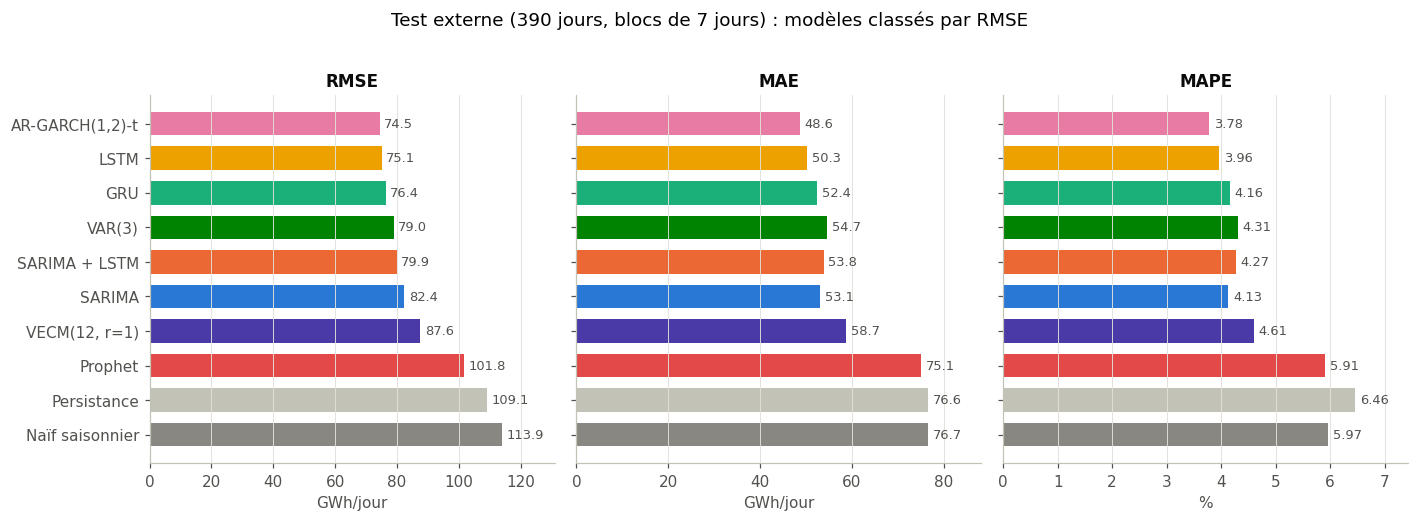

In [14]:
order = RANKING[::-1]  # meilleur modèle en haut
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), sharey=True)
for axis, metric, unit in zip(axes, ('RMSE', 'MAE', 'MAPE (%)'), ('GWh/jour', 'GWh/jour', '%')):
    values = comparison.loc[order, metric]
    bars = axis.barh(order, values, color=[COLORS[name] for name in order], height=0.68)
    axis.bar_label(bars, labels=[f'{value:.1f}' if unit != '%' else f'{value:.2f}' for value in values],
                   padding=3, fontsize=8.5, color='#52514e')
    axis.set(title=metric.replace(' (%)', ''), xlabel=unit, xlim=(0, values.max() * 1.15))
    axis.grid(axis='y', visible=False)
fig.suptitle('Test externe (390 jours, blocs de 7 jours) : modèles classés par RMSE', y=1.02)
fig.tight_layout()
save(fig, '6_comparaison_metriques.png')

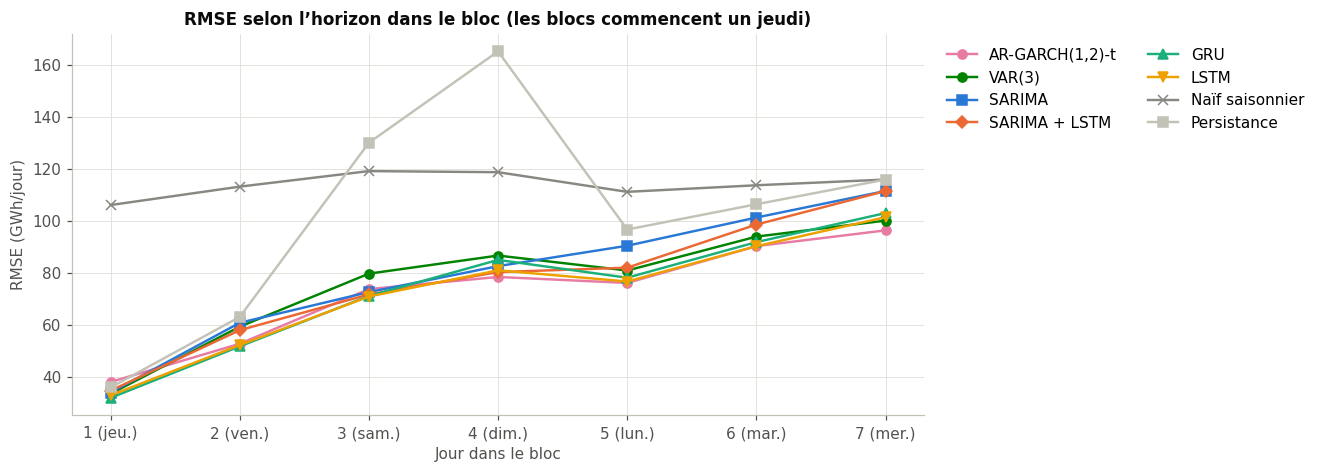

,1 (jeu.),2 (ven.),3 (sam.),4 (dim.),5 (lun.),6 (mar.),7 (mer.)
"AR-GARCH(1,2)-t",37.9,52.6,73.6,78.3,76.0,90.2,96.2
LSTM,32.7,52.1,70.8,80.9,76.5,90.1,101.3
GRU,31.8,51.6,71.0,84.9,78.0,91.7,102.9
VAR(3),33.4,59.2,79.6,86.5,80.8,93.8,100.0
SARIMA + LSTM,34.6,57.8,71.6,80.2,81.9,98.5,111.3
SARIMA,33.8,60.7,72.5,82.5,90.3,101.2,111.4
"VECM(12, r=1)",34.2,62.7,86.4,97.5,94.2,102.7,111.0
Prophet,99.6,96.4,105.8,102.9,96.4,104.0,106.9
Persistance,35.8,62.9,129.9,165.1,96.5,106.3,115.8
Naïf saisonnier,106.0,113.0,119.0,118.6,111.0,113.6,115.8


In [15]:
by_horizon = np.sqrt((errors[RANKING] ** 2).groupby(predictions['horizon']).mean())
by_horizon.index = [f'{h} ({day})' for h, day in zip(by_horizon.index, ['jeu.', 'ven.', 'sam.', 'dim.', 'lun.', 'mar.', 'mer.'])]
by_horizon.rename_axis('horizon (jour)').to_csv(EXPORTS / 'rmse_par_horizon.csv')

shown = ['AR-GARCH(1,2)-t', 'VAR(3)', 'SARIMA', 'SARIMA + LSTM', 'GRU', 'LSTM', 'Naïf saisonnier', 'Persistance']
markers = dict(zip(shown, 'oosD^vxs'))
fig, axis = plt.subplots(figsize=(10, 4.5))
for name in shown:
    axis.plot(range(1, BLOCK + 1), by_horizon[name], marker=markers[name], markersize=6,
              color=COLORS[name], linewidth=1.6, label=name)
axis.set(title='RMSE selon l’horizon dans le bloc (les blocs commencent un jeudi)',
         xlabel='Jour dans le bloc', ylabel='RMSE (GWh/jour)', xticks=range(1, BLOCK + 1))
axis.set_xticklabels(by_horizon.index)
axis.legend(ncol=2, loc='upper left', bbox_to_anchor=(1.01, 1))
save(fig, '6_rmse_par_horizon.png')
by_horizon.T.round(1)

## 6. Tests de Diebold–Mariano

Une RMSE plus faible sur la période observée ne suffit pas à démontrer une meilleure précision attendue. Le test de **Diebold–Mariano** compare deux modèles A et B sous l'hypothèse $H_0 : E[d_b]=0$.

Ici les prévisions quotidiennes mélangent les horizons 1 à 7. On compare donc **la perte moyenne de chaque bloc complet** :
$d_b = \frac{1}{7}\sum_{h=1}^7 [L(e_{A,b,h})-L(e_{B,b,h})]$,
avec $L(e)=e^2$ puis $L(e)=|e|$. Les 55 blocs complets (385 jours) alimentent les tests ; les 5 derniers jours sont conservés dans les métriques descriptives sur 390 jours, mais exclus des tests pour garder sept horizons identiques à chaque origine.

La statistique est $DM=\bar d/\sqrt{\widehat{\mathrm{Var}}(\bar d)}$. La variance HAC de Newey–West, à poids de Bartlett, autorise la dépendance entre blocs : $q=\lfloor4(n_b/100)^{2/9}\rfloor=3$ retards hebdomadaires. Les p-values bilatérales utilisent l'approximation normale asymptotique. Un DM négatif favorise A. Une analyse de sensibilité avec 1, 2 et 4 retards est exportée.

La correction de Harvey–Leybourne–Newbold pour un horizon fixe $h=7$ n'est pas appliquée à cette moyenne de plusieurs horizons. Les p-values restent approximatives avec seulement 55 origines et sous l'hypothèse de stabilité des différences de perte. Les modèles emboîtés (SARIMA et hybride) demandent également une interprétation prudente.

Les **45 paires** de modèles sont testées. La correction de **Holm sur toute la famille des 45 paires**, séparément pour chaque perte, évite de limiter artificiellement la famille aux comparaisons du gagnant choisi après observation du test. Les conclusions formelles utilisent la perte quadratique et les p-values ajustées ; la perte absolue est un complément exploratoire.

Références : [Grant (2026), comparaison sur la perte moyenne entre horizons](https://doi.org/10.1002/for.70150) ; [Diebold et Mariano (1995), article original](https://doi.org/10.1080/07350015.1995.10524599) ; [documentation `forecast::dm.test`](https://pkg.robjhyndman.com/forecast/reference/dm.test.html) (horizon fixe et estimateur Bartlett) ; [documentation statsmodels `cov_hac`](https://www.statsmodels.org/stable/generated/statsmodels.stats.sandwich_covariance.cov_hac.html) (variance HAC et règle de bande).

In [16]:
def diebold_mariano(errors_a, errors_b, horizon=BLOCK, power=2, max_lag=None):
    """DM sur la perte moyenne par bloc complet, variance HAC Bartlett, loi normale.

    `horizon` désigne le nombre d'horizons regroupés par origine (7 ici).
    Le bloc final incomplet est exclu. Une statistique négative favorise A.
    """
    a, b = np.asarray(errors_a, dtype=float), np.asarray(errors_b, dtype=float)
    if a.ndim != 1 or a.shape != b.shape or not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError('Deux vecteurs finis de même longueur sont nécessaires.')
    if not isinstance(horizon, (int, np.integer)) or horizon < 1 or power not in (1, 2):
        raise ValueError('Taille de bloc entière positive et perte absolue ou quadratique requises.')
    n_blocks = len(a) // horizon
    if n_blocks < 2:
        raise ValueError('Au moins deux blocs complets sont nécessaires.')
    complete = n_blocks * horizon
    d = ((np.abs(a[:complete]) ** power - np.abs(b[:complete]) ** power)
         .reshape(n_blocks, horizon).mean(axis=1))
    if max_lag is None:
        max_lag = min(int(np.floor(4 * (n_blocks / 100) ** (2 / 9))), n_blocks - 1)
    if not isinstance(max_lag, (int, np.integer)) or not 0 <= max_lag < n_blocks:
        raise ValueError('La bande HAC doit être entière, entre 0 et n_blocs - 1.')
    centred = d - d.mean()
    if np.allclose(d, 0, atol=0, rtol=0):
        return 0.0, 1.0
    if np.all(centred == 0):
        return float(np.copysign(np.inf, d.mean())), 0.0
    autocov = [np.dot(centred[k:], centred[:n_blocks - k]) / n_blocks for k in range(max_lag + 1)]
    long_run = autocov[0] + 2 * sum((1 - k / (max_lag + 1)) * autocov[k] for k in range(1, max_lag + 1))
    if long_run <= 0:
        raise ValueError('Variance HAC non positive ; vérifier les différences de perte.')
    statistic = float(d.mean() / np.sqrt(long_run / n_blocks))
    return statistic, float(2 * stats.norm.sf(abs(statistic)))


def holm(p_values):
    """P-values ajustées par Holm, dans l'ordre original."""
    p_values = np.asarray(p_values, dtype=float)
    if p_values.ndim != 1 or not np.isfinite(p_values).all() or ((p_values < 0) | (p_values > 1)).any():
        raise ValueError('Les p-values doivent être finies et comprises entre 0 et 1.')
    if not len(p_values):
        return p_values.copy()
    order = np.argsort(p_values)
    adjusted = np.maximum.accumulate((len(p_values) - np.arange(len(p_values))) * p_values[order])
    result = np.empty_like(adjusted)
    result[order] = np.minimum(adjusted, 1)
    return result


rows, sensitivity_rows = [], []
for i, model_a in enumerate(RANKING):
    for model_b in RANKING[i + 1:]:
        row = {'modèle A': model_a, 'modèle B': model_b}
        for loss, power in (('quadratique', 2), ('absolue', 1)):
            row[f'DM ({loss})'], row[f'p ({loss})'] = diebold_mariano(errors[model_a], errors[model_b], power=power)
        rows.append(row)
        for lag in (1, 2, 4):
            statistic, p_value = diebold_mariano(errors[model_a], errors[model_b], max_lag=lag)
            sensitivity_rows.append({'modèle A': model_a, 'modèle B': model_b,
                                     'retards HAC': lag, 'DM': statistic, 'p': p_value})

dm_pairs = pd.DataFrame(rows)
for loss in ('quadratique', 'absolue'):
    dm_pairs[f'p Holm ({loss})'] = holm(dm_pairs[f'p ({loss})'])
dm_pairs.to_csv(EXPORTS / 'diebold_mariano_toutes_paires.csv', index=False)
dm_sensitivity = pd.DataFrame(sensitivity_rows)
dm_sensitivity['p Holm'] = dm_sensitivity.groupby('retards HAC')['p'].transform(lambda p: holm(p.to_numpy()))
dm_sensitivity.to_csv(EXPORTS / 'diebold_mariano_sensibilite.csv', index=False)
print(f'{len(dm_pairs)} paires ; 55 blocs complets, 385 jours pour DM ; 390 jours pour les métriques.')
print(f'Rejets à 5 % : {(dm_pairs["p (quadratique)"] < 0.05).sum()} bruts, '
      f'{(dm_pairs["p Holm (quadratique)"] < 0.05).sum()} après Holm (45 paires).')

45 paires ; 55 blocs complets, 385 jours pour DM ; 390 jours pour les métriques.
Rejets à 5 % : 23 bruts, 7 après Holm (45 paires).


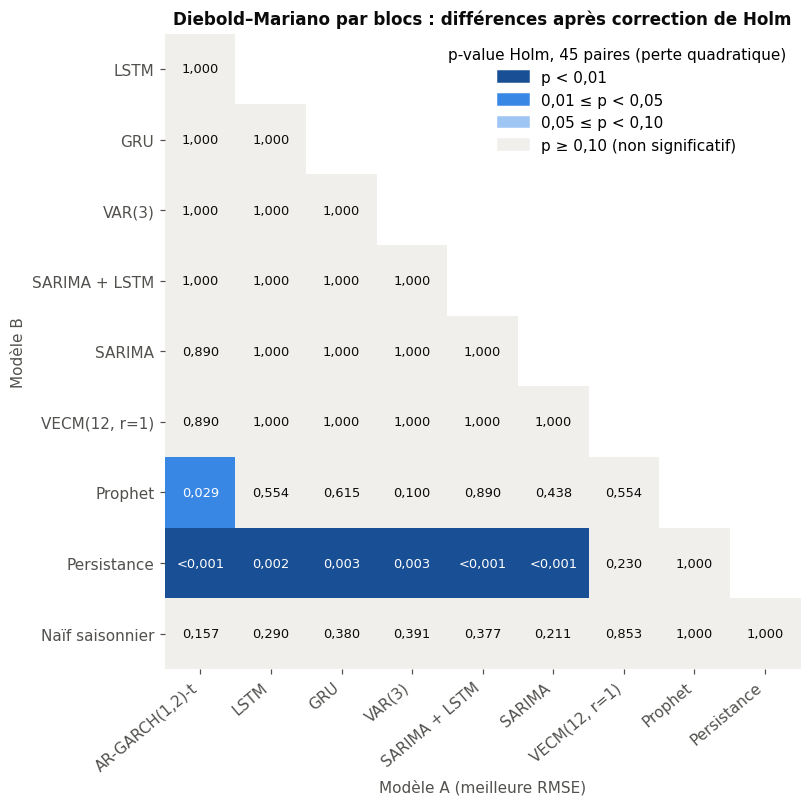

In [17]:
p_matrix = (dm_pairs.pivot(index='modèle B', columns='modèle A', values='p Holm (quadratique)')
            .reindex(index=RANKING[1:], columns=RANKING[:-1]))
bins = [0, 0.01, 0.05, 0.10, 1]
cmap = ListedColormap(['#184f95', '#3987e5', '#9ec5f4', '#f0efec'])
fig, axis = plt.subplots(figsize=(10, 7.5))
axis.imshow(np.ma.masked_invalid(p_matrix.to_numpy()), cmap=cmap, norm=BoundaryNorm(bins, cmap.N))
for (row, col), p_value in np.ndenumerate(p_matrix.to_numpy()):
    if np.isfinite(p_value):
        axis.text(col, row, '<0,001' if p_value < 0.001 else f'{p_value:.3f}'.replace('.', ','),
                  ha='center', va='center', fontsize=8.5, color='white' if p_value < 0.05 else '#0b0b0b')
axis.set_xticks(range(len(p_matrix.columns)), p_matrix.columns, rotation=40, ha='right')
axis.set_yticks(range(len(p_matrix.index)), p_matrix.index)
axis.set(xlabel='Modèle A (meilleure RMSE)', ylabel='Modèle B')
axis.grid(False)
axis.spines[:].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=color) for color in cmap.colors]
axis.legend(handles, ['p < 0,01', '0,01 ≤ p < 0,05', '0,05 ≤ p < 0,10', 'p ≥ 0,10 (non significatif)'],
            loc='upper right', frameon=False, title='p-value Holm, 45 paires (perte quadratique)')
axis.set_title('Diebold–Mariano par blocs : différences après correction de Holm')
save(fig, '6_diebold_mariano.png')

In [18]:
def dm_question(question, model_a, model_b):
    """Compare deux modèles ; A et B sont rangés pour que A ait la plus faible RMSE."""
    if model_a == model_b:
        raise ValueError('Choisir deux modèles distincts pour une question de comparaison.')
    if comparison.loc[model_a, 'RMSE'] > comparison.loc[model_b, 'RMSE']:
        model_a, model_b = model_b, model_a
    row = {'question': question, 'modèle A': model_a, 'modèle B': model_b,
           'RMSE A': comparison.loc[model_a, 'RMSE'], 'RMSE B': comparison.loc[model_b, 'RMSE']}
    for loss, power in (('quadratique', 2), ('absolue', 1)):
        row[f'DM ({loss})'], row[f'p ({loss})'] = diebold_mariano(errors[model_a], errors[model_b], power=power)
    pair = dm_pairs[((dm_pairs['modèle A'] == model_a) & (dm_pairs['modèle B'] == model_b)) |
                    ((dm_pairs['modèle A'] == model_b) & (dm_pairs['modèle B'] == model_a))].iloc[0]
    row['p Holm (quadratique)'] = pair['p Holm (quadratique)']
    row['p Holm (absolue)'] = pair['p Holm (absolue)']
    significant = row['p Holm (quadratique)'] < 0.05
    row['conclusion à 5 %'] = f'{model_a} plus précis' if significant else 'différence non significative'
    return row


best_network = min(('LSTM', 'GRU'), key=lambda name: comparison.loc[name, 'RMSE'])
questions = pd.DataFrame([
    dm_question('4.1 — GRU ou LSTM ?', 'GRU', 'LSTM'),
    dm_question('4.1 — meilleur réseau contre le naïf saisonnier', best_network, 'Naïf saisonnier'),
    dm_question('4.1 — meilleur réseau contre SARIMA', best_network, 'SARIMA'),
    dm_question('4.2 — le LSTM améliore-t-il le SARIMA ?', 'SARIMA + LSTM', 'SARIMA'),
    dm_question('4.2 — hybride contre meilleur réseau seul', 'SARIMA + LSTM', best_network),
    dm_question('3.2 — VAR contre SARIMA', 'VAR(3)', 'SARIMA'),
    dm_question('Meilleur modèle contre son premier concurrent', RANKING[0], RANKING[1]),
])
questions.to_csv(EXPORTS / 'diebold_mariano_questions.csv', index=False)
questions.style.format(precision=2).format('{:.4f}', subset=['p (quadratique)', 'p (absolue)', 'p Holm (quadratique)', 'p Holm (absolue)']).hide(axis='index')

question,modèle A,modèle B,RMSE A,RMSE B,DM (quadratique),p (quadratique),DM (absolue),p (absolue),p Holm (quadratique),p Holm (absolue),conclusion à 5 %
4.1 — GRU ou LSTM ?,LSTM,GRU,75.07,76.40,-1.23,0.2177,-2.04,0.0414,1.0000,0.9111,différence non significative
4.1 — meilleur réseau contre le naïf saisonnier,LSTM,Naïf saisonnier,75.07,113.93,-2.63,0.0085,-3.69,0.0002,0.2902,0.0081,différence non significative
4.1 — meilleur réseau contre SARIMA,LSTM,SARIMA,75.07,82.38,-1.13,0.2569,-0.91,0.3629,1.0000,1.0000,différence non significative
4.2 — le LSTM améliore-t-il le SARIMA ?,SARIMA + LSTM,SARIMA,79.92,82.38,-0.53,0.5946,0.29,0.7739,1.0000,1.0000,différence non significative
4.2 — hybride contre meilleur réseau seul,LSTM,SARIMA + LSTM,75.07,79.92,-1.21,0.2279,-1.26,0.2076,1.0000,1.0000,différence non significative
3.2 — VAR contre SARIMA,VAR(3),SARIMA,78.96,82.38,-0.69,0.4897,0.37,0.7085,1.0000,1.0000,différence non significative
Meilleur modèle contre son premier concurrent,"AR-GARCH(1,2)-t",LSTM,74.45,75.07,-0.11,0.9130,-0.55,0.5814,1.0000,1.0000,différence non significative


In [19]:
versus_best = dm_pairs[dm_pairs['modèle A'] == RANKING[0]].copy()
versus_best = versus_best.set_index('modèle B')[
    ['DM (quadratique)', 'p (quadratique)', 'p Holm (quadratique)', 'DM (absolue)', 'p (absolue)', 'p Holm (absolue)']]
versus_best.to_csv(EXPORTS / 'diebold_mariano_contre_meilleur.csv')
print(f'Meilleur modèle (RMSE) : {RANKING[0]}. Comparaison avec chacun des autres (Holm sur 45 paires) :')
versus_best.style.format('{:.3f}').format('{:.4f}', subset=[c for c in versus_best if c.startswith('p')])

Meilleur modèle (RMSE) : AR-GARCH(1,2)-t. Comparaison avec chacun des autres (Holm sur 45 paires) :


,DM (quadratique),p (quadratique),p Holm (quadratique),DM (absolue),p (absolue),p Holm (absolue)
modèle B,,,,,,
LSTM,-0.109,0.9130,1.0000,-0.551,0.5814,1.0000
GRU,-0.369,0.7124,1.0000,-1.306,0.1916,1.0000
VAR(3),-1.927,0.0540,1.0000,-2.901,0.0037,0.0968
SARIMA + LSTM,-1.114,0.2653,1.0000,-1.556,0.1198,1.0000
SARIMA,-2.086,0.0369,0.8897,-1.906,0.0566,1.0000
"VECM(12, r=1)",-2.102,0.0356,0.8897,-3.107,0.0019,0.0529
Prophet,-3.369,0.0008,0.0295,-4.336,0.0000,0.0005
Persistance,-5.111,0.0000,0.0000,-6.152,0.0000,0.0000
Naïf saisonnier,-2.860,0.0042,0.1568,-4.368,0.0000,0.0005


## Prévisions du 1er au 7 septembre 2026

Les réseaux sont réentraînés sur toutes les observations jusqu'au 31 août 2026, avec les époques choisies en validation. Ce sont des prévisions ponctuelles, sans intervalle. Le SARIMA est celui de la section 3.1 (`exports/previsions_7j.csv`).

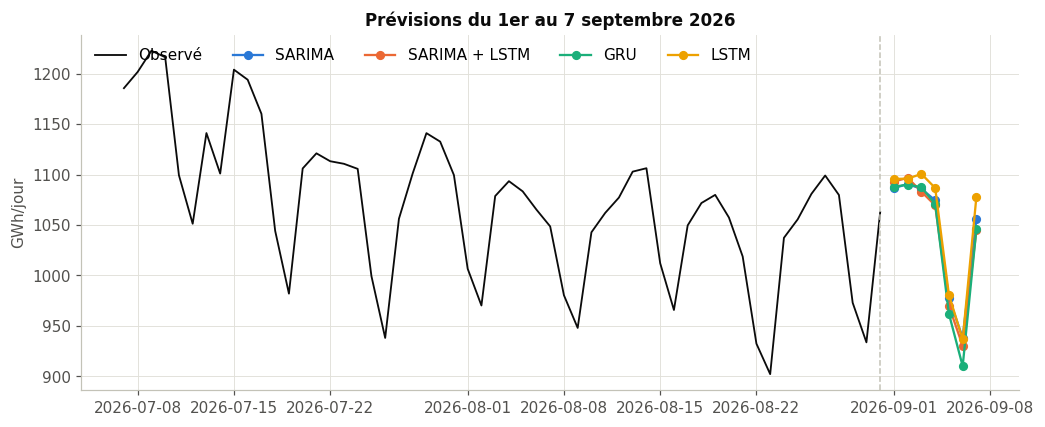

,jour,SARIMA,SARIMA + LSTM,GRU,LSTM
2026-09-01,mardi,1086.5,1093.1,1087.8,1095.6
2026-09-02,mercredi,1090.6,1096.8,1090.2,1096.0
2026-09-03,jeudi,1085.8,1083.0,1087.4,1100.6
2026-09-04,vendredi,1074.4,1069.5,1070.8,1086.7
2026-09-05,samedi,977.9,969.8,962.1,980.8
2026-09-06,dimanche,938.2,930.3,910.1,936.7
2026-09-07,lundi,1056.5,1044.8,1046.2,1078.3


In [20]:
final = pd.DataFrame(final_forecasts, index=final_dates)[['SARIMA', 'SARIMA + LSTM', 'GRU', 'LSTM']]
final.insert(0, 'jour', final.index.day_name(locale=None).map(
    {'Monday': 'lundi', 'Tuesday': 'mardi', 'Wednesday': 'mercredi', 'Thursday': 'jeudi',
     'Friday': 'vendredi', 'Saturday': 'samedi', 'Sunday': 'dimanche'}))
final.rename_axis('date').to_csv(EXPORTS / 'previsions_7j.csv')

recent = consumption.iloc[-56:]
fig, axis = plt.subplots(figsize=(11, 4.2))
axis.plot(recent.index, recent, color=COLORS['Observé'], linewidth=1.2, label='Observé')
for name in ('SARIMA', 'SARIMA + LSTM', 'GRU', 'LSTM'):
    axis.plot(final.index, final[name], marker='o', markersize=5, color=COLORS[name], label=name)
axis.axvline(consumption.index[-1], color='#c3c2b7', linestyle='--', linewidth=1)
axis.set(title='Prévisions du 1er au 7 septembre 2026', ylabel='GWh/jour')
axis.legend(ncol=5, loc='upper left')
save(fig, '6_previsions_septembre_2026.png')
final.round(1)

## Limites

- **Une seule période de test.** Les 390 jours couvrent un seul hiver ; les classements entre modèles proches (écarts de quelques GWh) peuvent changer d'une année à l'autre. Les tests de Diebold–Mariano autorisent une dépendance temporelle, mais ne garantissent pas la stabilité sur une autre période.
- **Validation courte et estivale.** Les 56 jours de validation (juin–août) servent à la fois à l'arrêt anticipé et au choix des entrées. Ils ne contiennent pas de vague de froid, alors que les plus grosses erreurs du test surviennent en hiver.
- **Réseaux compacts, peu réglés.** Une seule architecture (32 unités, fenêtre de 28 jours) a été essayée ; seules les entrées et les époques sont choisies. Un réglage plus large demanderait une validation plus longue pour ne pas surajuster.
- **Pas de météo.** Comme tous les modèles du groupe, aucune prévision météo n'est utilisée ; c'est la principale source d'erreur en hiver.
- **Hybride.** Les erreurs SARIMA d'apprentissage sont pseudo hors échantillon : les paramètres ont été estimés sur la même période. Le LSTM peut donc apprendre des erreurs un peu plus petites que celles du test.
- **Pas d'intervalles.** Les réseaux donnent des prévisions ponctuelles ; seuls SARIMA, VAR, VECM, AR-GARCH et Prophet fournissent des intervalles à 95 %.
- **Tests multiples.** 45 paires sont testées ; une p-value isolée proche de 0,05 doit être lue avec prudence (voir la correction de Holm appliquée aux 45 paires). Les tests utilisent 55 blocs complets ; l’approximation normale et la stabilité des écarts de perte restent des hypothèses. Prophet bénéficie de réestimations hebdomadaires, contrairement aux autres modèles.

## 6. Conclusion

Le texte ci-dessous est calculé à partir des résultats effectivement obtenus. « Meilleur » désigne la plus faible RMSE descriptive sur cette période, puis les tests précisent les différences étayées statistiquement.

In [21]:
from IPython.display import Markdown

best = RANKING[0]
best_scores = comparison.loc[best]
metric_winners = {metric: comparison[metric].idxmin() for metric in ('MSE', 'RMSE', 'MAE', 'MAPE (%)')}
close_models = versus_best.index[versus_best['p Holm (quadratique)'] >= 0.05].tolist()
network_gain = 100 * (1 - comparison.loc[best_network, 'RMSE'] / comparison.loc['Naïf saisonnier', 'RMSE'])
hybrid_gain = 100 * (1 - comparison.loc['SARIMA + LSTM', 'RMSE'] / comparison.loc['SARIMA', 'RMSE'])
hybrid_question = questions.loc[questions['question'].str.startswith('4.2 — le LSTM')].iloc[0]
hybrid_p = hybrid_question['p Holm (quadratique)']
hybrid_direction = 'réduit' if hybrid_gain > 0 else 'augmente'
text = (
    f'**Meilleur modèle observé selon la RMSE : {best}.** Sur les 390 jours du test externe, '
    f'il obtient MSE = {best_scores["MSE"]:.2f} (GWh/jour)², RMSE = {best_scores["RMSE"]:.2f} GWh/jour, '
    f'MAE = {best_scores["MAE"]:.2f} GWh/jour et MAPE = {best_scores["MAPE (%)"]:.2f} %.\n\n'
    f'Le meilleur réseau récurrent est **{best_network}** (RMSE {comparison.loc[best_network, "RMSE"]:.2f}), '
    f'contre {comparison.loc["LSTM" if best_network == "GRU" else "GRU", "RMSE"]:.2f} pour l’autre réseau. '
    f'Son gain de RMSE par rapport au naïf saisonnier est de {network_gain:.1f} % '
    '(un gain négatif indique une dégradation).\n\n'
    f'L’hybride **SARIMA + LSTM** obtient RMSE {comparison.loc["SARIMA + LSTM", "RMSE"]:.2f}, '
    f'contre {comparison.loc["SARIMA", "RMSE"]:.2f} pour SARIMA : il {hybrid_direction} la RMSE de '
    f'{abs(hybrid_gain):.1f} %. La différence est '
    f'{"significative" if hybrid_p < 0.05 else "non significative"} à 5 % après Holm '
    f'(p ajustée = {hybrid_p:.4f}).\n\n'
)
if close_models:
    text += (f'Les tests de Diebold–Mariano par blocs **ne distinguent pas significativement {best}** '
             f'des modèles suivants à 5 % après correction de Holm : {", ".join(close_models)}. '
             'Une différence non significative ne démontre pas leur équivalence.\n\n')
else:
    text += f'Les tests par blocs favorisent {best} face à chacun des autres modèles après Holm à 5 %.\n\n'
text += 'Gagnants par critère : ' + '; '.join(f'{metric} : {model}' for metric, model in metric_winners.items()) + '.\n\n'
text += (f'Pour une prévision ponctuelle dans ce cadre, **{best} est le candidat principal selon la RMSE observée**. '
         'Ce choix reste descriptif : les architectures ont été choisies sur la validation, et le classement final sur '
         'le test demande une nouvelle période indépendante avant de conclure à une supériorité durable. '
         'La validation est courte et estivale, le test couvre un seul hiver, aucune météo future n’est utilisée '
         'et les erreurs d’apprentissage de l’hybride sont pseudo hors échantillon. '
         'Prophet est réajusté chaque semaine ; cette différence de protocole et les limites des tests doivent être conservées.')
(EXPORTS / 'conclusion.md').write_text('## Conclusion\n\n' + text + '\n', encoding='utf-8')
display(Markdown(text))

metadata = {
    'python': platform.python_version(),
    'versions': {package: version(package) for package in ('torch', 'numpy', 'pandas', 'scipy', 'statsmodels', 'matplotlib')},
    'sha256_donnees': hashlib.sha256((ROOT / 'data/daily.csv').read_bytes()).hexdigest(),
    'test': {'debut': str(test_dates[0].date()), 'fin': str(test_dates[-1].date()), 'n': len(test_dates)},
    'dm': {'blocs_complets': len(test_dates) // BLOCK, 'jours': len(test_dates) // BLOCK * BLOCK,
           'variance': 'HAC Bartlett, 3 retards hebdomadaires', 'loi': 'normale asymptotique',
           'famille_holm': 45, 'sensibilite_retards': [1, 2, 4]},
    'meilleur_rmse': best,
}
(EXPORTS / 'verification.json').write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding='utf-8')
assert len(comparison) == 10 and len(dm_pairs) == 45 and len(final) == 7
assert np.isfinite(comparison[['MSE', 'RMSE', 'MAE', 'MAPE (%)']].to_numpy()).all()
assert np.isfinite(dm_pairs.filter(regex='^p ').to_numpy()).all()
assert np.isfinite(final.drop(columns='jour').to_numpy()).all()
print('Vérifications finales : 10 modèles, 4 métriques, 45 tests par perte, 7 prévisions ; valeurs finies.')

**Meilleur modèle observé selon la RMSE : AR-GARCH(1,2)-t.** Sur les 390 jours du test externe, il obtient MSE = 5543.30 (GWh/jour)², RMSE = 74.45 GWh/jour, MAE = 48.61 GWh/jour et MAPE = 3.78 %.

Le meilleur réseau récurrent est **LSTM** (RMSE 75.07), contre 76.40 pour l’autre réseau. Son gain de RMSE par rapport au naïf saisonnier est de 34.1 % (un gain négatif indique une dégradation).

L’hybride **SARIMA + LSTM** obtient RMSE 79.92, contre 82.38 pour SARIMA : il réduit la RMSE de 3.0 %. La différence est non significative à 5 % après Holm (p ajustée = 1.0000).

Les tests de Diebold–Mariano par blocs **ne distinguent pas significativement AR-GARCH(1,2)-t** des modèles suivants à 5 % après correction de Holm : LSTM, GRU, VAR(3), SARIMA + LSTM, SARIMA, VECM(12, r=1), Naïf saisonnier. Une différence non significative ne démontre pas leur équivalence.

Gagnants par critère : MSE : AR-GARCH(1,2)-t; RMSE : AR-GARCH(1,2)-t; MAE : AR-GARCH(1,2)-t; MAPE (%) : AR-GARCH(1,2)-t.

Pour une prévision ponctuelle dans ce cadre, **AR-GARCH(1,2)-t est le candidat principal selon la RMSE observée**. Ce choix reste descriptif : les architectures ont été choisies sur la validation, et le classement final sur le test demande une nouvelle période indépendante avant de conclure à une supériorité durable. La validation est courte et estivale, le test couvre un seul hiver, aucune météo future n’est utilisée et les erreurs d’apprentissage de l’hybride sont pseudo hors échantillon. Prophet est réajusté chaque semaine ; cette différence de protocole et les limites des tests doivent être conservées.

Vérifications finales : 10 modèles, 4 métriques, 45 tests par perte, 7 prévisions ; valeurs finies.
